# 00 The casualty thread: three kinds of question

*Teaching material. Not for clinical use.*

Among 56,763 US battle-injured in Afghanistan and Iraq, the case fatality of those injured in Afghanistan fell from 20.0% to 8.6% (E-82). Three things changed over those years that a medic would name first: tourniquets, blood transfusion, and faster transport from the point of injury.

**Before reading on, guess.** Of the deaths averted, what share do those three account for together?

- About a tenth
- About a quarter
- Under a half
- About three quarters
- Nearly all of them

Write the guess down. It is not marked, and the answer comes in the treatment section below.

In [1]:
%matplotlib inline
import collections

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from inference_labs import baseline, thread
from inference_labs.lenses import rules

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})
DARK, LIGHT, MID = "#7f2704", "#d9d9d9", "#08306b"   # battle or harm, other, published figure
PALE = "#6baed6"                                      # a second series: lighter, and drawn hollow or hatched
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 160)

# 100,000 synthetic casualties, seed 42, military cohort, every stream. Every result on them is a mechanism.
observed, truth = baseline.generator_sample()

## The idea, before any medicine

A detective arrives at a burgled house with five clues and three suspects. She is not proving anything, and she is not matching the scene to a page in a book. She is choosing the story that best explains the clues, and staying ready to drop it when the next clue arrives. Three different questions are mixed in her work. What happened here? Which suspect is most likely to have done it? And would a lock on the back door have stopped it? The first is answered by looking carefully, the second by comparing this house with others, and the third by an argument about a night that did not happen.

**Plain.** Every method in this repository is asked to answer one of three kinds of question: what happened (description), what will happen to this casualty (prediction), and what would happen if something were done differently (counterfactual). They need different evidence. A record can describe, and it can be used to predict, but on its own it cannot say what an intervention changed: the casualty who got the tourniquet is not the casualty who did not. Most misuse of a method is asking it the wrong kind of question.

**Developer.** Every lens sits behind one interface, `diagnose(casualty)`, `treat(casualty)` and `scorecard()`, and every lens is fed by one generator: a causal graph sampled forward, `generator.sample(n, seed, mix, setting, return_truth=True)`. The observed table holds what a record would hold. The truth table holds what no record can: for each casualty, both outcomes of tranexamic acid.

```python
observed, truth = generator.sample(100_000, seed=42, return_truth=True)
what_happened = observed.groupby("stream").size()                      # description: a count
who_is_at_risk = lens.diagnose(observed.iloc[0])                       # prediction: a fitted model, scored on new casualties
what_it_changed = truth["died_if_untreated"] & ~truth["died_if_treated"]   # counterfactual: only a generator holds both
```

A description costs a count. A prediction costs a fitted model and casualties it was not fitted on. A counterfactual costs either a randomised design or a causal structure that is assumed.

**Technical.** E-117 names the three tasks: description, prediction and counterfactual prediction. In notation, description summarises the distribution of recorded variables; prediction estimates $P(Y \mid X = x)$ for a new casualty with findings $x$; counterfactual prediction estimates an outcome under an action, such as $E[Y^{a=1}] - E[Y^{a=0}]$ for treatment $a$. The first two are functions of the distribution of what is recorded. The third is not: it needs knowledge of the causal structure that the data alone do not supply (E-117). Diagnosis, read this way, is abduction: of the hypotheses $h$ that could explain findings $x$, choose the one that best explains them, for instance the one with the largest $P(h \mid x)$, and revise it as $x$ grows.

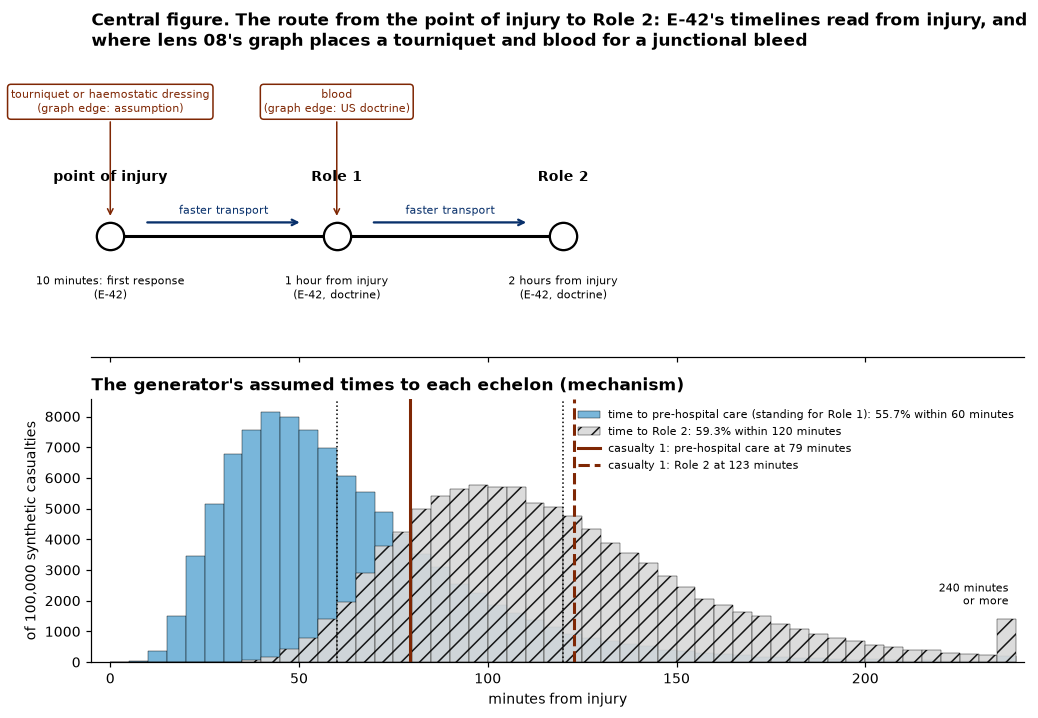

In [2]:
# Central figure: the route. The control: change it and run the cell again.
CASUALTY = 1     # which synthetic battle casualty's times to mark, from 1 to the number of battle casualties

route = thread.route()
mine = thread.casualty_times(CASUALTY)
at = {"point of injury": 0, "Role 1": 60, "Role 2": 120}       # each station drawn at its timeline, read from injury
fig, (ax, bx) = plt.subplots(2, 1, figsize=(9.5, 6.6), gridspec_kw={"height_ratios": [1.15, 1]}, sharex=True)
ax.plot([0, 120], [0, 0], color="black", linewidth=2, zorder=1)
for name, minutes in at.items():
    ax.scatter(minutes, 0, s=320, color="white", edgecolor="black", linewidth=1.5, zorder=3)
    ax.text(minutes, 0.32, name, ha="center", fontweight="bold")
ax.text(0, -0.36, route["first response"].split(":")[0] + ": first response\n(E-42)", ha="center", fontsize=7.5)
for a, b, words, label in route["legs"]:
    ax.text(at[b], -0.36, words.split(":")[0] + " from injury\n(E-42, " + label + ")", ha="center", fontsize=7.5)
    ax.annotate("", xy=(at[b] - 9, 0.08), xytext=(at[a] + 9, 0.08),
                arrowprops={"arrowstyle": "->", "color": MID, "linewidth": 1.5})
    ax.text((at[a] + at[b]) / 2, 0.13, "faster transport", ha="center", color=MID, fontsize=7.5)
for key, dy in (("tourniquet", 0.72), ("blood", 0.72)):
    name, where, label = route[key]
    ax.text(at[where], dy, f"{name.split(':')[0]}\n(graph edge: {label})", ha="center", fontsize=7.5, color=DARK,
            bbox={"boxstyle": "round", "facecolor": "white", "edgecolor": DARK})
    ax.annotate("", xy=(at[where], 0.1), xytext=(at[where], dy - 0.04),
                arrowprops={"arrowstyle": "->", "color": DARK, "linewidth": 1})
ax.set_ylim(-0.7, 1.05)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_title("Central figure. The route from the point of injury to Role 2: E-42's timelines read from injury, and\n"
             "where lens 08's graph places a tourniquet and blood for a junctional bleed", loc="left")

bins = np.arange(0, 241, 5)
for where, colour, hatch in (("Role 1", PALE, None), ("Role 2", LIGHT, "//")):
    bx.hist(np.clip(route["times"][where], 0, 240), bins=bins, color=colour, edgecolor="black", linewidth=0.3,
            hatch=hatch, alpha=0.9,
            label=f"time to {'pre-hospital care (standing for Role 1)' if where == 'Role 1' else 'Role 2'}: "
                  f"{route['within'][where]:.1%} within {at[where]} minutes")
    bx.axvline(at[where], color="black", linestyle=":", linewidth=1)
bx.axvline(mine["t_phec_min"], color=DARK, linewidth=2, label=f"casualty {CASUALTY}: pre-hospital care at "
                                                                f"{mine['t_phec_min']:.0f} minutes")
bx.axvline(mine["t_role2_min"], color=DARK, linewidth=2, linestyle="--",
           label=f"casualty {CASUALTY}: Role 2 at {mine['t_role2_min']:.0f} minutes")
bx.text(238, bx.get_ylim()[1] * 0.22, "240 minutes\nor more", ha="right", fontsize=7)
bx.set_xlim(-5, 242)
bx.set_xlabel("minutes from injury")
bx.set_ylabel(f"of {route['casualties']:,} synthetic casualties")
bx.legend(fontsize=7, frameon=False, loc="upper right")
bx.set_title("The generator's assumed times to each echelon (mechanism)", loc="left")
plt.tight_layout()
plt.show()

The upper panel is the route the casualty thread follows (D-4), from the point of injury through Role 1 to Role 2 (E-43). The 10-minute, 1-hour and 2-hour timelines are planning timelines from NATO doctrine, AJP-4.10 in the edition read (E-44), whose currency was not confirmed (D-28); they are doctrine, not measurement, and reading them as time from injury is an assumption. Two of the three interventions in the hook are placed where lens 08's graph places them for a junctional bleed. A tourniquet or haemostatic dressing sits at the point of injury, on edges that are all assumptions. Blood sits at Role 1: the edge from the injury to blood is US doctrine (E-86), not UK practice, and it is placed at Role 1 by assumed edges joined to an AJP-4.10 edge putting pre-hospital emergency care there (E-43). The third, faster transport, is the legs between stations.

The lower panel is the generator's clock: the time to pre-hospital care, which stands for reaching Role 1 as in lens 08, an assumption, and the time to Role 2. Both are drawn from distributions that are assumptions, so the shares inside each timeline are a **mechanism**, not a measurement of any evacuation chain. Change `CASUALTY` and run the cell again to mark another synthetic battle casualty's times.

### Terms used across the notebooks

- **E- and D- numbers.** An E- number, such as E-09, points to a row of the evidence register, `docs/EVIDENCE.md`, which gives a figure or finding with its source and how it was checked. Where a notebook says *the register*, it means this one. A D- number, such as D-23, points to a decision in the design document, `docs/DESIGN.md`, recorded with its reason.
- **Need for a life-saving intervention.** In the generator, a casualty needs one if bleeding significantly, or with a tension pneumothorax, a severe head injury or septic shock.
- **Brier score.** The mean, over casualties, of the squared difference between the probability a method gives and the outcome, scored as one if it happened and nought if not; lower is better. A rule gives no probability, so its call counts as one or nought, and its Brier score is the share misclassified.
- **GCS.** The Glasgow Coma Scale, a scored measure of conscious level.
- **AVPU.** A scale of conscious level: alert, responds to voice, responds to pain, unresponsive.
- **eFAST.** Extended focused assessment with sonography for trauma, an ultrasound scan.
- **Role 1, Role 2, Role 3.** Roles of care in NATO doctrine, AJP-4.10. The register records Role 1 as primary care, triage and pre-hospital emergency care, Role 2 in three forms, forward, basic and enhanced, and Role 3 as a deployed hospital with CT (E-43).

## By hand: a hundred admissions

Below are a hundred synthetic admissions from the generator's military cohort (seed 42), ten to a row, each marked by stream: **D** disease, **B** battle injury, **N** non-battle injury. A battle injury carries its mechanism after a stroke: **B/e** explosion, **B/s** small arms, **B/o** other.

1. On paper, count the admissions in each stream.
2. Then count the battle injuries by mechanism.
3. Compare each count with what the source figures lead you to expect. The generator's default mix is the UK field hospital admissions of one theatre: disease about 44%, battle injury about 30%, non-battle injury about 27% (E-36, derived from E-34 and E-35). Those shares are rounded and sum to 101, so the generator scales them to sum to one. The battle mechanisms are E-35's row counts: explosion 1,164, small arms 974, other 133.

In [3]:
admissions = thread.hundred()
letter = {"disease": "D", "battle": "B", "non_battle": "N"}
mech = {"explosion": "e", "small_arms": "s", "other": "o"}
marks = [letter[s] + (f"/{mech[m]}" if s == "battle" else "") for s, m in zip(admissions["stream"], admissions["mechanism"])]
for row in range(10):
    print("  ".join(f"{m:<3}" for m in marks[10 * row:10 * row + 10]))

N    B/s  N    B/o  D    N    N    N    D    B/s
D    N    B/e  N    B/e  D    B/s  D    N    B/s
N    D    N    N    N    D    B/e  D    D    B/s
N    N    D    D    B/s  D    D    B/e  D    B/e
B/e  N    B/s  D    N    N    D    D    B/e  D  
D    D    N    B/s  B/e  N    B/e  B/s  D    D  
B/e  B/s  B/e  N    B/s  B/e  B/s  D    D    B/o
D    D    N    D    D    D    D    B/o  B/s  N  
B/s  D    N    D    D    D    B/e  B/e  D    B/e
D    B/e  B/e  D    D    B/e  D    D    D    N  


In [4]:
# The same count in plain Python
by_stream = collections.Counter(admissions["stream"])
by_mechanism = collections.Counter(m for s, m in zip(admissions["stream"], admissions["mechanism"]) if s == "battle")

# and by the library
library_stream = thread.counts_by_stream(admissions)
library_mechanism = thread.counts_by_mechanism(admissions)
assert all(by_stream[s] == library_stream[s] for s in thread.STREAMS)
assert all(by_mechanism[m] == library_mechanism[m] for m in thread.MECHANISMS)

expected_stream = thread.expected_by_stream()
expected_mechanism = thread.expected_by_mechanism(library_stream["battle"])
table = pd.DataFrame(
    [{"group": thread.STREAM_NAMES[s], "counted": library_stream[s], "expected": expected_stream[s]} for s in thread.STREAMS]
    + [{"group": f"battle injury: {thread.MECHANISM_NAMES[m]}", "counted": library_mechanism[m],
        "expected": expected_mechanism[m]} for m in thread.MECHANISMS])
print("paper, plain Python and library agree")
table.round(1)

paper, plain Python and library agree


,group,counted,expected
0,disease,41,43.6
1,battle injury,35,29.7
2,non-battle injury,24,26.7
3,battle injury: explosion,18,17.9
4,battle injury: small arms,14,15.0
5,battle injury: other,3,2.0


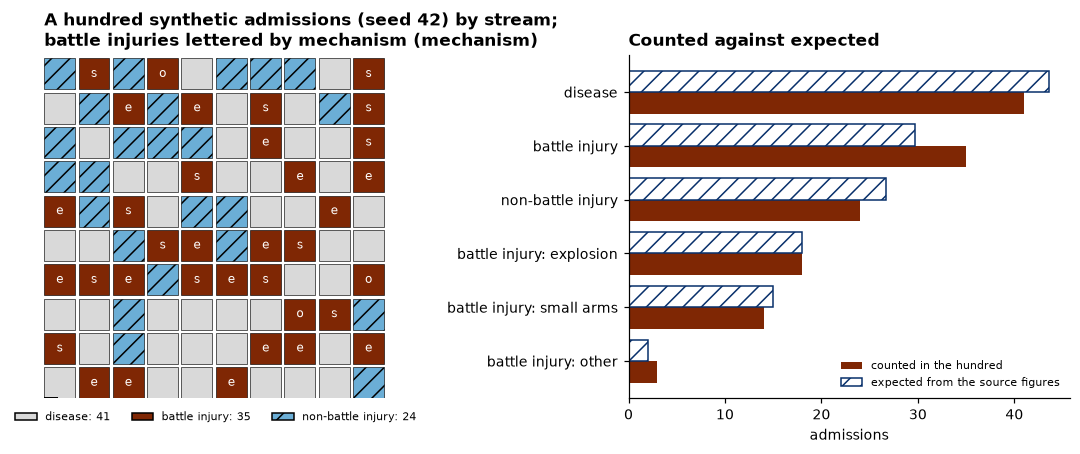

In [5]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1, 1.15]})
colour = {"disease": LIGHT, "battle": DARK, "non_battle": PALE}
for k, (s, m) in enumerate(zip(admissions["stream"], admissions["mechanism"])):
    r, c = divmod(k, 10)
    ax.add_patch(plt.Rectangle((c, 9 - r), 0.9, 0.9, facecolor=colour[s], edgecolor="black", linewidth=0.4,
                               hatch="//" if s == "non_battle" else None))
    if s == "battle":
        ax.text(c + 0.45, 9 - r + 0.45, mech[m], ha="center", va="center", color="white", fontsize=8)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect("equal")
ax.axis("off")
for s in thread.STREAMS:
    ax.bar(0, 0, color=colour[s], edgecolor="black", hatch="//" if s == "non_battle" else None,
           label=f"{thread.STREAM_NAMES[s]}: {library_stream[s]}")
ax.legend(fontsize=7, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=3)
ax.set_title("A hundred synthetic admissions (seed 42) by stream;\nbattle injuries lettered by mechanism (mechanism)",
             loc="left")
y = np.arange(len(table))
bx.barh(y + 0.2, table["counted"], 0.4, color=DARK, label="counted in the hundred")
bx.barh(y - 0.2, table["expected"], 0.4, color="white", edgecolor=MID, hatch="//",
        label="expected from the source figures")
bx.set_yticks(y, table["group"])
bx.invert_yaxis()
bx.set_xlabel("admissions")
bx.legend(fontsize=7, frameon=False, loc="lower right")
bx.set_title("Counted against expected", loc="left")
plt.tight_layout()
plt.show()

That is description: counting what is there. Written as notation, with stream shares $\pi_s$ the expected count among $n$ admissions is $n\pi_s$, and the count itself varies around it by chance; on a hundred, by several admissions either way. The generator's mix is one theatre's admissions (E-34 to E-36). It does not describe a future operation, and any other mix is an assumption.

## Diagnosis: describing and predicting

The three tasks of data science (E-117) give the casualty three questions. The source's own example comes from health records; the third column restates it for the casualty thread.

In [6]:
pd.DataFrame(thread.THREE_QUESTIONS, columns=["task (E-117)", "the source's example", "for the casualty"])

,task (E-117),the source's example,for the casualty
0,description,How can women with a history of stroke be grouped?,"Who is injured, and how?"
1,prediction,What is the probability of a stroke next year?,Who will die of bleeding?
2,counterfactual prediction,Will starting a statin reduce the risk?,Does tranexamic acid reduce those deaths?


**Description: who arrives.** From 1 April 2006 to 30 November 2014, 7,601 UK Service personnel were admitted to UK field hospitals in Afghanistan: 3,347 (44.0%) for natural causes and 4,220 for injuries (E-34). The injury rows split into battle 2,271 and non-battle 2,019; those rows sum to 4,290, not 4,220, so the shares are approximate (E-35). Disease about 44%, battle injury about 30% and non-battle injury about 27% is arithmetic on those rows, not a figure the source states (E-36). The UK Joint Theatre Trauma Registry describes a different group, combat casualties rather than all admissions: 2,792 casualties with 14,252 injuries and 608 deaths (22%); about 70% of hostile-action casualties were from explosive munitions, and extremities were 43% of injuries (E-84).

**Prediction: who dies, and when.** Of 4,596 US battlefield deaths from 2001 to 2011, 87.3% happened before the casualty reached a treatment facility (E-39). Of those deaths before a facility, 24.3% (976) were judged potentially survivable, and 90.9% of those were from haemorrhage (E-40); the site of the lethal haemorrhage was truncal in 67.3%, junctional in 19.2% and extremity in 13.5% (E-41). Those are US deaths. The UK picture after arrival is a different group again: of 71 UK combat casualties in Iraq and Afghanistan who reached a treatment facility alive and later died, 38 (54%) died within 24 hours; 33 (47%) died of isolated head injury, 13 (18%) had an unsurvivable head injury with other injuries, and 15 (21%) died of haemorrhage after severe lower limb trauma, often with abdominal and pelvic injury (E-128).

The US figures count deaths mostly before any facility; the UK figures count deaths after one was reached. Neither describes the other's casualties. They are set side by side only to show where each group's deaths come from: before a facility, among the deaths judged potentially survivable, mostly haemorrhage; after one was reached, in the UK figures, mostly head injury and haemorrhage.

**Common is not lethal.** In a UK trauma team cohort the extremities were the commonest injured region, 44% of injuries against 7% for the torso (E-38); in the UK registry they were 43% of injuries (E-84). Yet among the potentially survivable deaths, the haemorrhage was mostly truncal (E-41). A method scored on how often it is right overall will do well by getting limbs right. The generator reproduces this gap, but not as a finding: its share of bleeding deaths at each site is set to E-41 by construction, while its share of casualties bleeding at each site is an assumption.

10,834 synthetic battle casualties bleeding significantly; 1,999 of them would die of bleeding without tranexamic acid, counted from injury (mechanism)


,share of those bleeding,share of bleeding deaths,E-41
site,,,
truncal,0.351,0.693,0.673
junctional,0.151,0.190,0.192
extremity,0.498,0.117,0.135


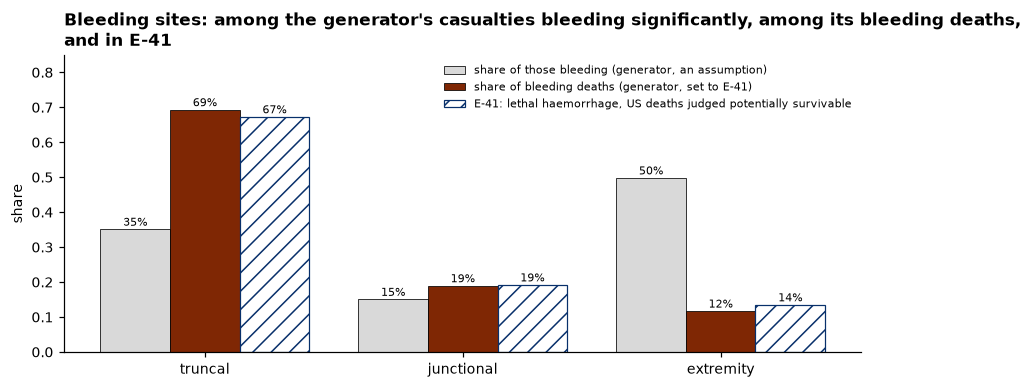

In [7]:
split = thread.site_split()
print(f"{split.attrs['bleeding']:,} synthetic battle casualties bleeding significantly; "
      f"{split.attrs['deaths']:,} of them would die of bleeding without tranexamic acid, counted from injury (mechanism)")
display(split.round(3))
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(split))
ax.bar(x - 0.27, split["share of those bleeding"], 0.27, color=LIGHT, edgecolor="black", linewidth=0.5,
       label="share of those bleeding (generator, an assumption)")
ax.bar(x, split["share of bleeding deaths"], 0.27, color=DARK, edgecolor="black", linewidth=0.5,
       label="share of bleeding deaths (generator, set to E-41)")
ax.bar(x + 0.27, split["E-41"], 0.27, color="white", edgecolor=MID, hatch="//", linewidth=0.8,
       label="E-41: lethal haemorrhage, US deaths judged potentially survivable")
for i, (a, b, c) in enumerate(split[["share of those bleeding", "share of bleeding deaths", "E-41"]].to_numpy()):
    for dx, v in ((-0.27, a), (0, b), (0.27, c)):
        ax.text(i + dx, v + 0.01, f"{v:.0%}", ha="center", fontsize=7)
ax.set_xticks(x, split.index)
ax.set_ylabel("share")
ax.set_ylim(0, 0.85)
ax.legend(fontsize=7, frameon=False, loc="upper right")
ax.set_title("Bleeding sites: among the generator's casualties bleeding significantly, among its bleeding deaths,\n"
             "and in E-41", loc="left")
plt.tight_layout()
plt.show()

## Treatment: the counterfactual question

**The answer to the hook.** A simulation estimated 3,672 deaths averted (3,209 to 4,244) and attributed 44.2% of them to the three interventions: tourniquets 12.9%, blood transfusion 23.8% and faster prehospital transport 7.5% (E-82). The other 55.8% of the deaths averted are not attributed to those three. The attribution comes from a simulation, not a measurement, and it is US data.

That is the third kind of question, and it cannot be answered by counting. The same record that shows case fatality falling cannot by itself show what tourniquets did: that needs a comparison with what would have happened without them, and a record holds only what did happen. The study of the 2009 sixty-minute evacuation mandate, on 21,089 US casualties in Afghanistan from 2001 to 2014, is explicit about this. Its authors list historical controls, a post hoc analysis of non-randomised data, survival bias in their transfusion analysis, and several factors changing at once, so that only a descriptive reading of their data was viable; only 37.3% of casualties had matched flight and facility records (E-81).

On the generator the counterfactual can be read directly, because the generator holds both outcomes of tranexamic acid for every casualty. That is possible only because it was built with them: the effect is an input, not a discovery.

29,925 synthetic battle casualties, of whom 482 die from bleeding before pre-hospital care, where the generator gives the drug, and are left out. Among the 29,443 alive at pre-hospital care, deaths from bleeding (mechanism):
  if none were given tranexamic acid: 1,517 (5.15 per 100)
  if all were given it:               1,087 (3.69 per 100)
  alive only if given it: 431; dead only if given it: 1 (1 of them given it more than 3 hours after injury, where the generator's effect is harm)
A further 4 would die of bleeding only if given the drug, at or before pre-hospital care: the drug is not yet given, so they are counted alive either way.


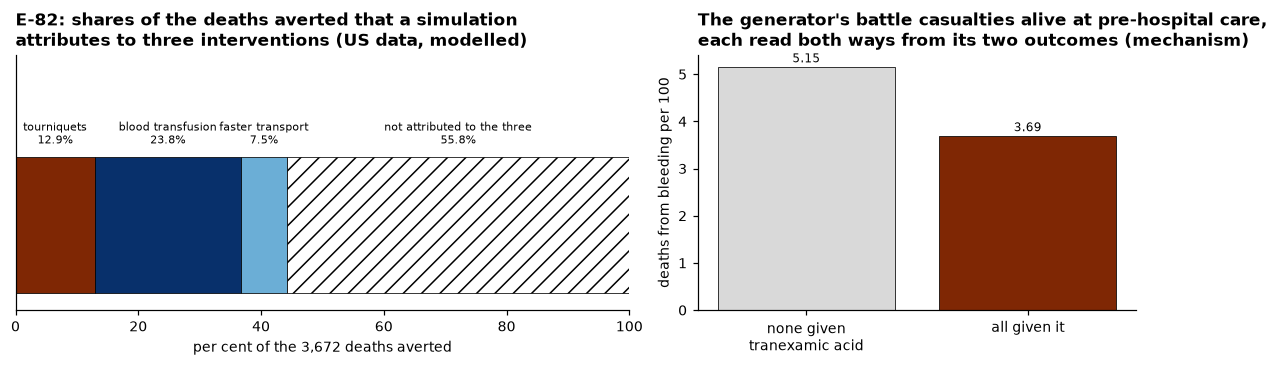

In [8]:
both = thread.tranexamic_both_ways()
print(f"{both['battle casualties']:,} synthetic battle casualties, of whom {both['died before care']:,} die from "
      f"bleeding before pre-hospital care, where the generator gives the drug, and are left out. Among the "
      f"{both['casualties']:,} alive at pre-hospital care, deaths from bleeding (mechanism):")
print(f"  if none were given tranexamic acid: {both['deaths if none treated']:,} ({both['per 100 if none treated']:.2f} per 100)")
print(f"  if all were given it:               {both['deaths if all treated']:,} ({both['per 100 if all treated']:.2f} per 100)")
print(f"  alive only if given it: {both['saved']:,}; dead only if given it: {both['harmed']:,} "
      f"({both['harmed, given after 3 hours']:,} of them given it more than 3 hours after injury, where the generator's "
      f"effect is harm)")
print(f"A further {both['death with the drug before care']:,} would die of bleeding only if given the drug, at or before "
      f"pre-hospital care: the drug is not yet given, so they are counted alive either way.")

fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 3.4), gridspec_kw={"width_ratios": [1.4, 1]})
parts = (("tourniquets", 12.9, DARK, None), ("blood transfusion", 23.8, MID, None),
         ("faster transport", 7.5, PALE, None), ("not attributed to the three", 55.8, "white", "//"))
left = 0
for name, share, colour, hatch in parts:
    ax.barh(0, share, left=left, color=colour, edgecolor="black", hatch=hatch, linewidth=0.5)
    ax.text(left + share / 2, 0.48, f"{name}\n{share}%", ha="center", fontsize=7)
    left += share
ax.set_xlim(0, 100)
ax.set_ylim(-0.5, 1)
ax.set_yticks([])
ax.set_xlabel("per cent of the 3,672 deaths averted")
ax.set_title("E-82: shares of the deaths averted that a simulation\nattributes to three interventions (US data, modelled)",
             loc="left")
bx.bar([0, 1], [both["per 100 if none treated"], both["per 100 if all treated"]], color=[LIGHT, DARK],
       edgecolor="black", linewidth=0.5)
for i, v in enumerate([both["per 100 if none treated"], both["per 100 if all treated"]]):
    bx.text(i, v + 0.1, f"{v:.2f}", ha="center", fontsize=8)
bx.set_xticks([0, 1], ["none given\ntranexamic acid", "all given it"])
bx.set_ylabel("deaths from bleeding per 100")
bx.set_title("The generator's battle casualties alive at pre-hospital care,\neach read both ways from its two "
             "outcomes (mechanism)", loc="left")
plt.tight_layout()
plt.show()

Casualties who die of bleeding before pre-hospital care are left out because the drug is not yet given. The generator draws one time of death for both outcomes and acts on the probability of death, not on its timing, so a casualty can also hold a death that comes only with the drug and falls before the drug is given; that casualty is alive at care and is counted alive either way. Counting either kind would put down to the drug deaths it could not reach. On the generator the drug's effect is known exactly for those alive at care, including the harm it does when given after 3 hours, which the generator takes from an exploratory analysis (E-23) of a civilian trial (E-22). No record of real casualties holds both columns. Lens 07 shows what happens when the effect has to be estimated from who happened to be treated.

## The failure: a description read as a counterfactual

A before-and-after comparison describes. It becomes a counterfactual claim the moment the fall is put down to one change, and it is wrong whenever something else changed at the same time.

The construction below makes that happen on the generator. **Before:** 100,000 synthetic casualties at the default mix, none given tranexamic acid. **After:** a fresh 100,000 in which the share of battle casualties has halved to 15%, an assumption, and every battle casualty is given the drug. Deaths from bleeding are counted per 100 synthetic casualties, from injury, including those who die before reaching care. The drug is given at pre-hospital care, so in the after cohort a battle casualty who dies of bleeding before it dies whether or not the drug was meant for them. Read naively, the fall is the drug's. Read from both outcomes of the after casualties, the drug's share of the fall is known, and the rest is the change in mix. Both cohorts are constructed; neither is a description of any real period.

In [9]:
once = thread.before_after()
spread = thread.before_after_spread()
share = spread["drug"] / spread["fall"]
print(f"before: {once['before']:.2f} deaths from bleeding per 100 casualties, from injury; after: {once['after']:.2f} "
      f"(mechanism)")
print(f"naive reading: the drug cut deaths by {once['fall']:.2f} per 100, {once['fall'] / once['before']:.0%} of the "
      f"before figure")
print(f"from both outcomes of the after casualties: had none been given it, {once['after, none treated']:.2f} per 100, "
      f"so the drug accounts for {once['drug']:.2f} of the fall and the change in mix, with sampling, for {once['mix']:.2f}")
print(f"across 20 further pairs of samples (seeds 43 to 62): the fall runs from {spread['fall'].min():.2f} to "
      f"{spread['fall'].max():.2f} per 100, the drug's part from {spread['drug'].min():.2f} to {spread['drug'].max():.2f}, "
      f"so the drug accounts for {share.min():.0%} to {share.max():.0%} of the fall")

before: 2.00 deaths from bleeding per 100 casualties, from injury; after: 0.84 (mechanism)
naive reading: the drug cut deaths by 1.16 per 100, 58% of the before figure
from both outcomes of the after casualties: had none been given it, 1.05 per 100, so the drug accounts for 0.21 of the fall and the change in mix, with sampling, for 0.95
across 20 further pairs of samples (seeds 43 to 62): the fall runs from 1.11 to 1.28 per 100, the drug's part from 0.18 to 0.25, so the drug accounts for 15% to 21% of the fall


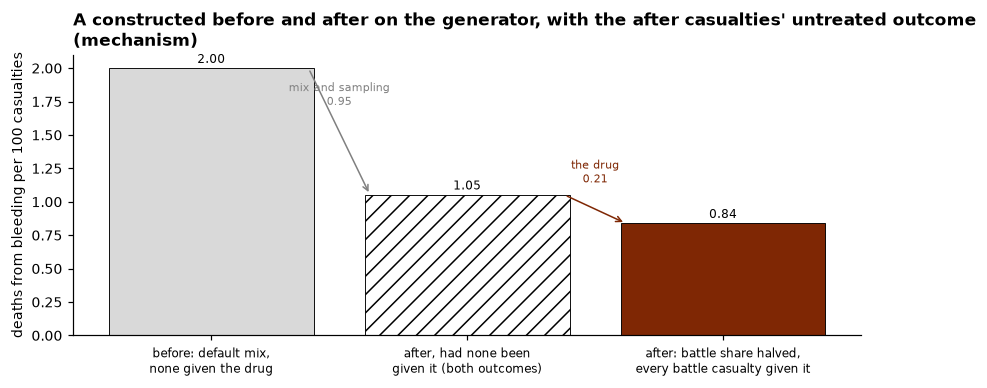

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
vals = [once["before"], once["after, none treated"], once["after"]]
labels = ["before: default mix,\nnone given the drug", "after, had none been\ngiven it (both outcomes)",
          "after: battle share halved,\nevery battle casualty given it"]
ax.bar(range(3), vals, color=[LIGHT, "white", DARK], edgecolor="black", hatch=[None, "//", None], linewidth=0.6)
for i, v in enumerate(vals):
    ax.text(i, v + 0.04, f"{v:.2f}", ha="center", fontsize=8)
ax.annotate("", xy=(0.62, once["after, none treated"]), xytext=(0.38, once["before"]),
            arrowprops={"arrowstyle": "->", "color": "grey"})
ax.text(0.5, (once["before"] + once["after, none treated"]) / 2 + 0.2, f"mix and sampling\n{once['mix']:.2f}",
        ha="center", fontsize=7.5, color="grey")
ax.annotate("", xy=(1.62, once["after"]), xytext=(1.38, once["after, none treated"]),
            arrowprops={"arrowstyle": "->", "color": DARK})
ax.text(1.5, (once["after"] + once["after, none treated"]) / 2 + 0.2, f"the drug\n{once['drug']:.2f}",
        ha="center", fontsize=7.5, color=DARK)
ax.set_xticks(range(3), labels, fontsize=8)
ax.set_ylabel("deaths from bleeding per 100 casualties")
ax.set_title("A constructed before and after on the generator, with the after casualties' untreated outcome\n"
             "(mechanism)", loc="left")
plt.tight_layout()
plt.show()

The naive reading is not a small error: the drug did lower deaths in the after cohort, but by a fraction of the fall it is credited with. The real record has no third bar. Several factors changing at once is among the reasons E-81's authors give for keeping to a descriptive reading of their data. E-82's attribution is a simulation, not a count, and leaves 55.8% of the deaths averted unattributed to the three interventions.

## Scorecard: the ten lenses, and the yardstick each is held to

Notebook 00 has no lens of its own. Its scorecard is the map of the ten and the yardstick they share.

**The map.** Each lens has a diagnosis case and a treatment case. Below, each case is placed under the kind of question it asks. The sorting is this notebook's own reading. The fit, native or weak, is read from each lens's scorecard, not typed here. Two patterns stand out. Diagnosis is nearly always prediction. And several treatment cases are predictions too: the ABC score and lens 04's treatment tree predict who will need blood; they do not estimate what blood does.

In [11]:
lens_map = thread.lens_map()
lens_map

,diagnosis case,diagnosis asks,diagnosis fit,treatment case,treatment asks,treatment fit
lens,,,,,,
01 Rules,MPTT-24 priority,prediction,native,ABC score: who is likely to need massive transfusion,prediction,native
02 Frequentist,"a test's error rates, by cohort and setting",description,native,a randomised trial read as a test and an interval,counterfactual prediction,weak
03 Bayesian,belief in bleeding into the abdomen after a scan,prediction,native,"belief that tranexamic acid helps, from a trial and a prior",counterfactual prediction,weak
04 Decision trees,need for an intervention from four signs,prediction,native,who gets blood first: who is bleeding,prediction,native
05 Stochastic processes,chance of dying from bleeding in the next hour,prediction,weak,the benefit of tranexamic acid left at a delay,counterfactual prediction,native
06 Connectionist,a constructed image: is the oval there?,prediction,native,need for an intervention from four signs,prediction,weak
07 Causal,"who gets scanned, and how that biases measured accuracy",description,weak,"the effect of tranexamic acid, naive, adjusted and true",counterfactual prediction,native
08 Knowledge graph,"findings to candidate injuries, by traversal",prediction,native,injury to intervention to the echelon that holds it,description,native
09 Reinforcement learning,which question to ask next,prediction,weak,"a dosing policy's value, estimated from logs of another",counterfactual prediction,native


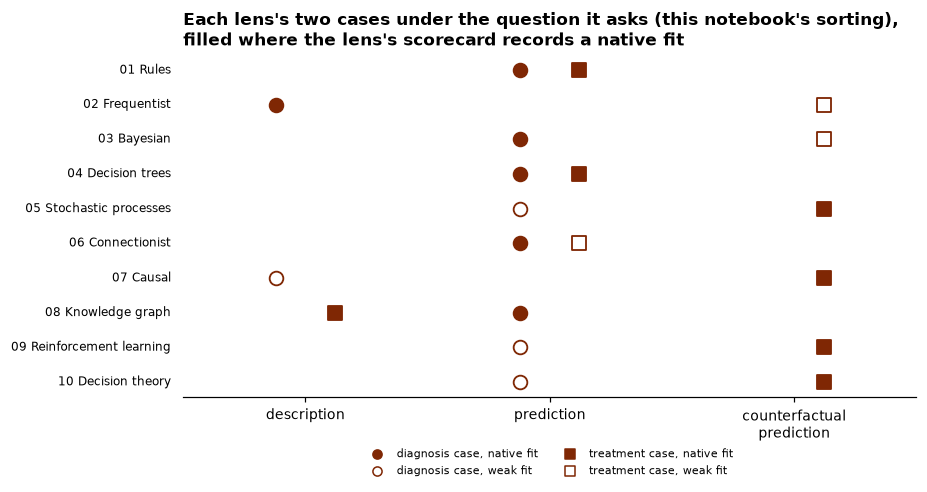

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
col = {q: i for i, q in enumerate(thread.QUESTIONS)}
for row, (lens, r) in enumerate(lens_map.iterrows()):
    y = len(lens_map) - 1 - row
    for case, dx, marker in (("diagnosis", -0.12, "o"), ("treatment", 0.12, "s")):
        native = r[f"{case} fit"] == "native"
        ax.scatter(col[r[f"{case} asks"]] + dx, y, s=80, marker=marker, color=DARK if native else "white",
                   edgecolor=DARK, linewidth=1.2, zorder=3)
    ax.text(-0.55, y, lens, ha="right", va="center", fontsize=8)
ax.set_xticks(range(3), ["description", "prediction", "counterfactual\nprediction"])
ax.set_yticks([])
ax.set_xlim(-0.5, 2.5)
ax.spines["left"].set_visible(False)
for case, marker in (("diagnosis case", "o"), ("treatment case", "s")):
    ax.scatter([], [], marker=marker, color=DARK, label=f"{case}, native fit")
    ax.scatter([], [], marker=marker, color="white", edgecolor=DARK, label=f"{case}, weak fit")
ax.legend(fontsize=7, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title("Each lens's two cases under the question it asks (this notebook's sorting),\n"
             "filled where the lens's scorecard records a native fit", loc="left")
plt.tight_layout()
plt.show()

**The yardstick.** Every lens is scored on the seven axes of D-21 against the same baseline, the MPTT-24 (D-9), read as its figure was published, with the text reading beside it, labelled as validated because E-09 was measured with the GCS (D-24). Axes 1, 2 and 6 are computed on the generator and carry the **mechanism** label; 3, 4 and 5 are stated; axis 7 is net benefit at a threshold of 0.10 for every lens (D-26), the value implied by weighing a miss nine times a false alarm, an assumption. The baseline's own scorecard, as lens 01 computes it, is below; every later lens's scorecard sets its own columns beside these two.

In [13]:
yardstick = thread.yardstick()
with pd.option_context("display.max_colwidth", None):
    display(yardstick)
print(baseline.died_before_care_note(baseline.died_before_care_count(observed, truth),
                                     "the 100,000 casualties behind these two columns"))

,"diagnosis: MPTT-24, figure (as published)","diagnosis: MPTT-24, text (as validated)"
axis,,
1 Discrimination (mechanism),"sensitivity 60.0%, specificity 78.6%: Priority 1 against need for a life-saving intervention, all 100,000 synthetic casualties, disease included. The scorecard's figures are on every stream of the military cohort, disease included, and, where they say so, on battle casualties alone; the comparison with E-09 holds for the injured only, of whom 26.5% need a life-saving intervention against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23). Battle casualties are among the injured; of them alone 50.2% need a life-saving intervention, against 47.6% Priority 1 in the military registry (E-09), so they are not a milder cohort than the one the rule was validated on.","sensitivity 61.4%, specificity 77.8% on the same casualties. Across 20 further samples the text reading's sensitivity less the figure's is higher: the difference runs from +1.4 to +1.9 points across 20 seeds; its specificity less the figure's is lower: the difference runs from -0.8 to -0.7 points across 20 seeds"
2 Calibration (mechanism),"Brier 0.245, where lower is better; it flags 11.2 points more of the casualties than are in need (share flagged minus share in need +0.112). A rule gives no probability, so the Brier score is the share misclassified. Battle casualties alone: Brier 0.318, where lower is better; it flags 5.7 points fewer of the battle casualties than are in need (share flagged minus share in need -0.057)","Brier 0.249, where lower is better; it flags 12.1 points more of the casualties than are in need (share flagged minus share in need +0.121). Battle casualties alone: Brier 0.314, where lower is better; it flags 4.6 points fewer of the battle casualties than are in need (share flagged minus share in need -0.046). Across 20 further samples the text reading's Brier score less the figure's is, on every stream, higher, so worse: the difference runs from +0.003 to +0.004 across 20 seeds; and among the battle casualties alone, lower, so better: the difference runs from -0.007 to -0.004 across 20 seeds. Its share flagged minus share in need less the figure's is, on every stream, higher: the difference runs from +0.009 to +0.010 across 20 seeds; and among the battle casualties alone, higher: the difference runs from +0.011 to +0.014 across 20 seeds"
3 Uncertainty expressed,"None: a priority, not a probability or an interval","None: a priority, not a probability or an interval"
4 What it needed,"Rules only at the point of use. Its thresholds descend from the MPTT, derived by logistic regression on 3,654 patients with complete data (E-01, E-02, E-08)",Rules only at the point of use (E-08); this is the reading that matches the GCS on which E-09 was measured
5 Readability,"A medic can follow it at the point of care: six yes-or-no steps, one observation each","A medic can follow it at the point of care: six yes-or-no steps, one observation each"
"6 Robustness, setting changed (mechanism)","With the scan in hospital: sensitivity 60.0%, specificity 78.6%; Brier 0.245, where lower is better; it flags 11.2 points more of the casualties than are in need (share flagged minus share in need +0.112). Battle casualties alone: Brier 0.318, where lower is better; it flags 5.7 points fewer of the battle casualties than are in need (share flagged minus share in need -0.057). Unchanged, because the generator draws the same physiology in either setting, so this axis cannot show what moving from hospital observations to the point of injury would do (E-11)","With the scan in hospital: sensitivity 61.4%, specificity 77.8%; Brier 0.249, where lower is better; it flags 12.1 points more of the casualties than are in need (share flagged minus share in need +0.121). Battle casualties alone: Brier 0.314, where lower is better; it flags 4.6 points fewer of the battle casualties t

482 of the 100,000 casualties behind these two columns died from bleeding before pre-hospital care in the generator, without tranexamic acid, and are included


## The analogy, and where it breaks

**What it resembles.** The detective's evidence board: clues pinned and strung to suspects, the strings thickening as evidence arrives, one story chosen because it explains the most. Diagnosis framed as abduction works this way, and each lens is a different way of weighing the strings.

**Where it breaks.** A detective's suspects are distinct and one of them did it. A casualty can have several things wrong at once: 13 (18%) of the UK casualties who died after reaching care had an unsurvivable head injury with other injuries (E-128). The generator is simpler than either: each synthetic casualty has at most one condition, because each condition it draws belongs to a single patient type, and the patient type is drawn once. And a detective can wait for the last clue. A medic often has to act on the story before the evidence is complete, which is where the costs of lens 10 come in.